# SPRT-TANDEM tutorial: is the particle drifting to the right or to the left?

This notebook runs the SPRT-TANDEM on a small synthetic dataset, from generating the data to drawing the speed-accuracy tradeoff curve.

- **Problem**: a jittery particle is carried by a flow. You watch it frame by frame and must decide whether the flow goes to the right (class 1) or to the left (class 0), **as early and as accurately as possible**.
- **Steps**: (1) look at the data → (2) train a classifier → (3) compute the log-likelihood ratio (LLR) with the TANDEM formula → (4) decide when to stop with the SPRT and draw the speed-accuracy tradeoff (SAT) curve.
- **How to run**: in Google Colab, choose **Runtime → Run all** from the menu (in JupyterLab: **Run → Run All Cells**). The whole notebook takes about one minute on a CPU, and no GPU is needed. The only libraries required are NumPy, Matplotlib, and PyTorch.

Because the data are synthetic, **the true LLR can be computed in closed form**, which lets us check how accurate the estimated LLR is.

If you opened this notebook in Google Colab, choose **File → Save a copy in Drive** to keep your changes.

For a casual introduction to the SPRT and the SPRT-TANDEM, see the [README of this repository](https://github.com/Akinori-F-Ebihara/SPRT-TANDEM-tutorial).

In [1]:
%matplotlib inline
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ===== Settings (change the numbers and run the notebook again to see how the results change) =====
DELTA = 0.5      # strength of the flow: the mean horizontal step is +DELTA for class 1 and -DELTA for class 0
RHO = 0.5        # inertia: how much of the previous jitter carries over to the next frame (0 = independent frames)
T = 100          # length of one sequence (number of frames)
N_TRAIN = 20000  # number of training sequences
N_TEST = 10000   # number of test sequences
EPOCHS = 8       # number of training epochs
SEED = 0
SHOW_ANIMATION = False   # set to True to watch the particles being carried by the flow

T_START = time.time()
T_SHOW = min(60, T)      # number of frames shown in the figures
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

# Colors: class 0 = blue, class 1 = red. The remaining colors are for curves that do not belong to a class.
C0, C1 = "#145094", "#94142E"
INK, GRAY, PALE, AMBER = "#1F2430", "#6C757D", "#C9CED6", "#C98500"
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})


def class_handles():
    """Legend entries for the two classes"""
    return [Line2D([], [], color=C1, lw=2.5, label="Class 1: flow to the right"),
            Line2D([], [], color=C0, lw=2.5, label="Class 0: flow to the left")]


print(f"PyTorch {torch.__version__} | device = {device} | CPU threads = {torch.get_num_threads()}")

PyTorch 2.15.0+cu132 | device = cpu | CPU threads = 2


## 1. Data: a jittery particle carried by a flow

Picture a leaf floating on a river. The current carries it along, while wind and ripples make it jitter. A single frame does not tell you which way the river flows.

At each frame $t$ we observe the **displacement of the particle during that frame**, $x^{(t)} = (h^{(t)},\ v^{(t)})$, where $h^{(t)}$ is the horizontal step and $v^{(t)}$ is the vertical step.

| | Class 1 (flow to the right) | Class 0 (flow to the left) |
|---|---|---|
| Mean horizontal step | $+\delta$ | $-\delta$ |
| Mean vertical step | $0$ | $0$ |
| Jitter | Standard deviation 1. A fraction $\rho$ of the previous jitter carries over (inertia) | Same as class 1 |

In formulas, the observation is $x^{(t)} = (\pm\delta,\ 0) + e^{(t)}$, and the jitter $e^{(t)}$ follows $e^{(t)} = \rho\, e^{(t-1)} + \sqrt{1-\rho^2}\; z^{(t)}$ with $e^{(1)} = z^{(1)}$, where $z^{(t)}$ is standard normal noise drawn independently for each frame and each direction. The jitter therefore has standard deviation 1 at every frame.

- With $\rho = 0$ the frames are independent and identically distributed (i.i.d.): each horizontal step is drawn from a normal distribution with mean $\pm\delta$ and variance 1. This is the classical setting of Wald's SPRT.
- With $\rho > 0$ consecutive frames move in similar ways. Real data such as video frames are correlated in the same manner, and the i.i.d. assumption no longer holds.

In [2]:
def make_walks(n_per_class, T, delta, rho, rng):
    """Generate the motion of the particles.
    Returns  x: (2n, T, 2)  step in each frame (horizontal, vertical)
             y: (2n,)       class (1 = flow to the right, 0 = flow to the left)"""
    n = 2 * n_per_class
    y = np.repeat(np.array([0, 1]), n_per_class)
    drift = np.zeros((n, 2), dtype=np.float32)
    drift[:, 0] = np.where(y == 1, delta, -delta)                 # the flow acts only in the horizontal direction
    noise_scale = float(np.sqrt(1.0 - rho ** 2))
    x = np.empty((n, T, 2), dtype=np.float32)
    e = rng.standard_normal((n, 2), dtype=np.float32)             # jitter (standard deviation 1)
    x[:, 0] = drift + e
    for t in range(1, T):
        e = rho * e + noise_scale * rng.standard_normal((n, 2), dtype=np.float32)   # part of the previous jitter carries over
        x[:, t] = drift + e
    perm = rng.permutation(n)
    return x[perm], y[perm]


def to_position(x):
    """Add up the steps to get positions (starting from the origin). Shape: (number of sequences, T + 1, 2)"""
    return np.concatenate([np.zeros((len(x), 1, 2), dtype=np.float32), x.cumsum(axis=1)], axis=1)


x_train, y_train = make_walks(N_TRAIN // 2, T, DELTA, RHO, rng)
x_test, y_test = make_walks(N_TEST // 2, T, DELTA, RHO, rng)
pos_test = to_position(x_test)
print("x_train:", x_train.shape, "  y_train:", y_train.shape, "  x_test:", x_test.shape)
print("First 3 frames of the first sequence (horizontal, vertical):\n", np.round(x_train[0, :3], 2), "  class:", y_train[0])

x_train: (20000, 100, 2)   y_train: (20000,)   x_test: (10000, 100, 2)
First 3 frames of the first sequence (horizontal, vertical):
 [[-1.64  0.27]
 [-1.06 -1.02]
 [ 0.16  0.22]]   class: 0


### Look at the two classes

- Left: paths of the particles (all start from the black dot at the origin)
- Middle: horizontal position over time (dashed lines: the mean position due to the flow alone)
- Right: distribution of the horizontal step in a single frame

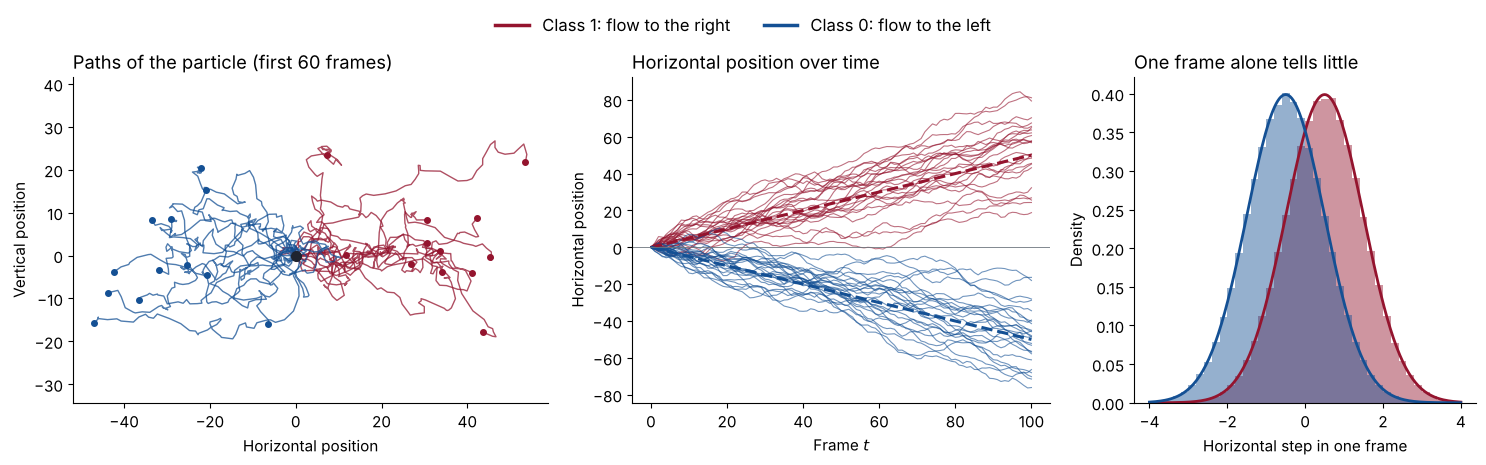

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.7), gridspec_kw=dict(width_ratios=[1.25, 1.1, 0.9]))

ax = axs[0]
for cls, col in ((1, C1), (0, C0)):
    for i in np.where(y_test == cls)[0][:12]:
        ax.plot(pos_test[i, :T_SHOW + 1, 0], pos_test[i, :T_SHOW + 1, 1], color=col, lw=1.0, alpha=0.75)
        ax.plot(pos_test[i, T_SHOW, 0], pos_test[i, T_SHOW, 1], "o", color=col, ms=4)
ax.plot(0, 0, "o", color=INK, ms=7, zorder=5)
ax.set(xlabel="Horizontal position", ylabel="Vertical position")
ax.set_title(f"Paths of the particle (first {T_SHOW} frames)", loc="left")
ax.set_aspect("equal", adjustable="datalim")

ax = axs[1]
frames = np.arange(T + 1)
for cls, col in ((1, C1), (0, C0)):
    for i in np.where(y_test == cls)[0][:25]:
        ax.plot(frames, pos_test[i, :, 0], color=col, lw=0.8, alpha=0.6)
ax.plot(frames, DELTA * frames, color=C1, lw=2.2, ls="--")
ax.plot(frames, -DELTA * frames, color=C0, lw=2.2, ls="--")
ax.axhline(0, color=GRAY, lw=0.6)
ax.set(xlabel="Frame $t$", ylabel="Horizontal position")
ax.set_title("Horizontal position over time", loc="left")

ax = axs[2]
bins = np.linspace(-4, 4, 41)
grid = np.linspace(-4, 4, 200)
for cls, col, mu in ((1, C1, DELTA), (0, C0, -DELTA)):
    ax.hist(x_test[y_test == cls][:, :, 0].ravel(), bins=bins, density=True, color=col, alpha=0.45)
    ax.plot(grid, np.exp(-(grid - mu) ** 2 / 2) / np.sqrt(2 * np.pi), color=col, lw=2)
ax.set(xlabel="Horizontal step in one frame", ylabel="Density")
ax.set_title("One frame alone tells little", loc="left")

fig.legend(handles=class_handles(), loc="upper center", ncol=2, frameon=False, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

**What the figure shows**

- **A single frame hardly separates the two classes** (right panel: the two distributions overlap heavily).
- **Accumulating frames makes the difference visible** (middle panel: the two bundles move apart), although the classes are still mixed in the early frames.
- The vertical motion carries no information about the class. Which component matters is something the model has to learn from the data.

The next figure reveals one sequence step by step. **At which frame would you answer?**

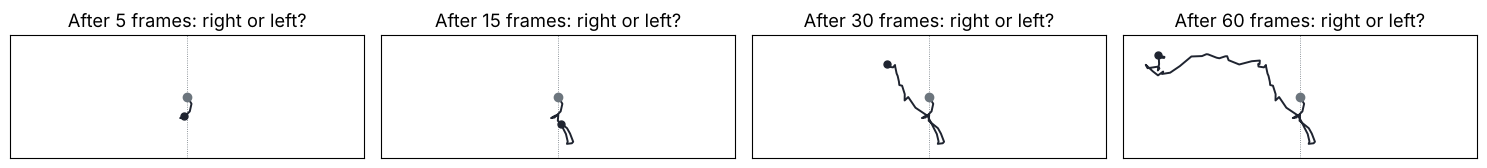

Answer: flow to the left (class 0)


In [4]:
# Pick a sequence that first moves in the wrong direction (fall back to the first sequence if there is none)
sign = 2 * y_test - 1                                                     # +1 for class 1, -1 for class 0
t_early = min(10, T_SHOW)
cand = np.where((pos_test[:, t_early, 0] * sign < -1) & (pos_test[:, T_SHOW, 0] * sign > 0.25 * T_SHOW))[0]
i_quiz = int(cand[0]) if len(cand) else 0

steps_shown = sorted(set(min(n, T_SHOW) for n in (5, 15, 30, 60)))
lim = np.abs(pos_test[i_quiz, :T_SHOW + 1, 0]).max() * 1.15
lim_v = max(np.abs(pos_test[i_quiz, :T_SHOW + 1, 1]).max() * 1.3, 0.3 * lim)
fig, axs = plt.subplots(1, len(steps_shown), figsize=(15, 15 / 4 * lim_v / lim + 0.7), squeeze=False)
for ax, n in zip(axs[0], steps_shown):
    ax.axvline(0, color=GRAY, lw=0.6, ls=":")
    ax.plot(pos_test[i_quiz, :n + 1, 0], pos_test[i_quiz, :n + 1, 1], color=INK, lw=1.4)
    ax.plot(pos_test[i_quiz, n, 0], pos_test[i_quiz, n, 1], "o", color=INK, ms=5)
    ax.plot(0, 0, "o", color=GRAY, ms=6)
    ax.set(xlim=(-lim, lim), ylim=(-lim_v, lim_v), xticks=[], yticks=[])
    ax.set_aspect("equal")
    ax.set_title(f"After {n} frames: right or left?")
    for s in ("top", "right"):
        ax.spines[s].set_visible(True)
fig.tight_layout()
plt.show()
print("Answer:", "flow to the right (class 1)" if y_test[i_quiz] == 1 else "flow to the left (class 0)")

In [5]:
# (Optional) Watch the particles being carried by the flow. Set SHOW_ANIMATION = True in the first code cell and run the notebook again.
if SHOW_ANIMATION:
    from matplotlib import animation
    from IPython.display import HTML, display

    idx = np.concatenate([np.where(y_test == 1)[0][:6], np.where(y_test == 0)[0][:6]])
    cols = [C1 if y_test[i] == 1 else C0 for i in idx]
    lim = np.abs(pos_test[idx, :T_SHOW + 1]).max() * 1.05
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.set(xlim=(-lim, lim), ylim=(-0.6 * lim, 0.6 * lim), xlabel="Horizontal position", ylabel="Vertical position")
    ax.set_aspect("equal")
    ax.plot(0, 0, "o", color=INK, ms=6)
    lines = [ax.plot([], [], color=c, lw=1.0, alpha=0.8)[0] for c in cols]
    dots = [ax.plot([], [], "o", color=c, ms=5)[0] for c in cols]
    ax.legend(handles=class_handles(), loc="upper center", ncol=2, framealpha=0.85, edgecolor="none")
    title = ax.set_title("Frame 0", loc="left")

    def update(t):
        for ln, dt, i in zip(lines, dots, idx):
            ln.set_data(pos_test[i, :t + 1, 0], pos_test[i, :t + 1, 1])
            dt.set_data([pos_test[i, t, 0]], [pos_test[i, t, 1]])
        title.set_text(f"Frame {t}")
        return lines + dots + [title]

    anim = animation.FuncAnimation(fig, update, frames=T_SHOW + 1, interval=120)
    plt.close(fig)
    display(HTML(anim.to_jshtml()))
else:
    print("Set SHOW_ANIMATION = True in the first code cell to show the animation here.")

Set SHOW_ANIMATION = True in the first code cell to show the animation here.


## 2. Ground truth: the true log-likelihood ratio

The SPRT uses the log-likelihood ratio (LLR) of all the frames observed up to the current one,

$$\Lambda_t = \log \frac{p(x^{(1)},\dots,x^{(t)} \mid y=1)}{p(x^{(1)},\dots,x^{(t)} \mid y=0)} = \sum_{u=1}^{t} \lambda_u,
\qquad \lambda_u = \log \frac{p(x^{(u)} \mid x^{(1)},\dots,x^{(u-1)},\, y=1)}{p(x^{(u)} \mid x^{(1)},\dots,x^{(u-1)},\, y=0)}.$$

Notation: the capital $\Lambda_t$ is the **cumulative LLR** up to the frame $t$, and the small $\lambda_u$ is the **LLR of a single step**, that is, the evidence that the frame $x^{(u)}$ adds given the frames before it. The sum on the right is the chain rule of conditional probabilities and always holds. (Mind the difference from the SPRT-TANDEM paper, Ebihara et al., ICLR 2021, where $\lambda$ denotes the cumulative LLR.)

We know how the data were generated, which lets us write the LLR down. In terms of the horizontal steps $h^{(t)}$,

$$\lambda_1 = 2\delta\, h^{(1)}, \qquad \lambda_u = 2\delta\, \frac{h^{(u)} - \rho\, h^{(u-1)}}{1+\rho} \quad (u \ge 2),
\qquad \Longrightarrow \qquad \Lambda_t = 2\delta\left[\; h^{(1)} + \sum_{u=2}^{t} \frac{h^{(u)} - \rho\, h^{(u-1)}}{1+\rho} \right].$$

- Derivation: factorize the joint density with the chain rule, use the fact that each frame depends only on the previous one (a first-order Markov process), and take the ratio of the resulting normal densities.
- If $\rho = 0$, then $\Lambda_t = 2\delta \sum_u h^{(u)}$. With $\delta = 0.5$, the LLR is **the horizontal position itself**.
- If $\rho > 0$, the part of a new step that could be predicted from the previous step, $\rho\, h^{(u-1)}$, is subtracted, and only the remainder counts as new evidence.

The LLR is measured in nats because we use the natural logarithm.

With real data the true LLR is unknown. Below, we estimate the LLR **without using this formula** and use the formula only to check the answer.

In [6]:
def true_llr(x, delta=DELTA, rho=RHO):
    """True cumulative log-likelihood ratio (capital Lambda). Shape: (number of sequences, T).
    Only the horizontal step carries information about the class."""
    h = x[:, :, 0].astype(np.float64)
    inc = np.empty_like(h)                                               # LLR of each single step (small lambda)
    inc[:, 0] = 2 * delta * h[:, 0]
    inc[:, 1:] = 2 * delta * (h[:, 1:] - rho * h[:, :-1]) / (1 + rho)
    return inc.cumsum(axis=1)                                            # cumulative LLR (capital Lambda)


llr_true = true_llr(x_test)
print("Shape of the true LLR:", llr_true.shape)
print(f"Mean at the last frame: class 1 = {llr_true[y_test == 1, -1].mean():+.1f}, class 0 = {llr_true[y_test == 0, -1].mean():+.1f}")

Shape of the true LLR: (10000, 100)
Mean at the last frame: class 1 = +17.0, class 0 = -16.9


## 3. Model: feature extractor + temporal integrator

We build a small version of the SPRT-TANDEM network.

1. **Feature extractor**: a small network that turns the step of each frame (two numbers) into a feature vector.
2. **Temporal integrator**: an LSTM that reads the features of $N+1$ consecutive frames and outputs the class logits. The intermediate outputs of the LSTM are used as well. A single pass therefore gives the outputs for windows of length $1, 2, \dots, N+1$.
3. **Loss**: the ordinary cross-entropy, averaged over all windows and all window lengths (the multiplet cross-entropy).

$N$ is the order of the Markov assumption: the number of preceding frames whose correlation with the current frame is taken into account. We train two models, $N=1$ (the dependence on the previous frame is taken into account) and $N=0$ (the frames are treated as independent).

In [7]:
class TandemNet(nn.Module):
    """Feature extractor -> temporal integrator (LSTM) -> class logits"""

    def __init__(self, order, in_dim=2, feat_dim=16, hidden=16, num_classes=2):
        super().__init__()
        self.order = order                                                  # Markov order N
        self.feature_extractor = nn.Sequential(nn.Linear(in_dim, feat_dim), nn.ReLU(), nn.Linear(feat_dim, feat_dim))
        self.temporal_integrator = nn.LSTM(feat_dim, hidden, batch_first=True)
        self.classifier = nn.Linear(hidden, num_classes)

    def forward(self, x):
        """x: (B, T, 2) -> logits: (B, T - N, N + 1, K)
        logits[:, w, k] are the class logits computed from the first k + 1 frames of the w-th window."""
        B = x.shape[0]
        feats = self.feature_extractor(x)                                   # (B, T, feat): features of each frame
        windows = feats.unfold(1, self.order + 1, 1).permute(0, 1, 3, 2)    # (B, T - N, N + 1, feat): windows slid by one frame
        W = windows.shape[1]
        h, _ = self.temporal_integrator(windows.reshape(B * W, self.order + 1, -1))
        return self.classifier(h).reshape(B, W, self.order + 1, -1)


def multiplet_cross_entropy(logits, y):
    """Cross-entropy averaged over all windows and all window lengths (1 to N + 1 frames)"""
    B, W, L, K = logits.shape
    return F.cross_entropy(logits.reshape(-1, K), y.repeat_interleave(W * L))


def train(x, y, order, epochs=EPOCHS, batch_size=250, lr=5e-3):
    torch.manual_seed(SEED)
    net = TandemNet(order).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    steps = epochs * int(np.ceil(len(x) / batch_size))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    t0 = time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(x))
        total = 0.0
        for i in range(0, len(x), batch_size):
            idx = perm[i:i + batch_size]
            loss = multiplet_cross_entropy(net(x[idx].to(device)), y[idx].to(device))
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
            total += loss.item() * len(idx)
        print(f"N = {order} | epoch {ep + 1}/{epochs} | loss {total / len(x):.4f} | {time.time() - t0:5.1f} s")
    return net


x_train_t, y_train_t = torch.from_numpy(x_train), torch.from_numpy(y_train)
x_test_t = torch.from_numpy(x_test)
print("Shape of the logits (N = 1):", tuple(TandemNet(order=1)(x_train_t[:4]).shape), " = (batch, windows, frames within a window, classes)")

Shape of the logits (N = 1): (4, 99, 2, 2)  = (batch, windows, frames within a window, classes)


In [8]:
net_n1 = train(x_train_t, y_train_t, order=1)   # takes the dependence on the previous frame into account
net_n0 = train(x_train_t, y_train_t, order=0)   # treats the frames as independent

N = 1 | epoch 1/8 | loss 0.6688 |   2.0 s


N = 1 | epoch 2/8 | loss 0.5731 |   4.0 s


N = 1 | epoch 3/8 | loss 0.5673 |   6.0 s


N = 1 | epoch 4/8 | loss 0.5670 |   7.9 s


N = 1 | epoch 5/8 | loss 0.5668 |  10.0 s


N = 1 | epoch 6/8 | loss 0.5663 |  12.1 s


... (6 outputs left out)

N = 0 | epoch 5/8 | loss 0.5827 |   5.5 s


N = 0 | epoch 6/8 | loss 0.5822 |   6.5 s


N = 0 | epoch 7/8 | loss 0.5823 |   7.4 s


N = 0 | epoch 8/8 | loss 0.5821 |   8.5 s


## 4. The TANDEM formula: from classifier outputs to the LLR

$$\hat\Lambda_t \;=\; \sum_{u=N+1}^{t} \log\frac{\hat p\big(y=1 \mid x^{(u-N)},\dots,x^{(u)}\big)}{\hat p\big(y=0 \mid x^{(u-N)},\dots,x^{(u)}\big)}
\;-\; \sum_{u=N+2}^{t} \log\frac{\hat p\big(y=1 \mid x^{(u-N)},\dots,x^{(u-1)}\big)}{\hat p\big(y=0 \mid x^{(u-N)},\dots,x^{(u-1)}\big)}$$

(The two classes are equally frequent, and the prior term therefore vanishes. While $t \le N$, the output for all the frames seen up to $t$ is used as it is.)

- First term: add the outputs for the windows of length $N+1$.
- Second term: subtract the outputs for the overlaps between neighboring windows (length $N$), which would otherwise be counted twice.
- One step at a time: for $t \ge N+2$, the increment $\hat\lambda_t = \hat\Lambda_t - \hat\Lambda_{t-1}$ is the output for the window that ends at the frame $t$ minus the output for the same window without the frame $t$. It estimates the single-step LLR $\lambda_t$, with the past limited to the last $N$ frames.
- With a softmax output, the logarithm of the posterior ratio is simply **the difference of the logits**. We therefore add and subtract a "score" for each class and take the difference at the end.

In [9]:
def tandem_scores(logits):
    """TANDEM formula. logits: (B, T - N, N + 1, K) -> score of each class: (B, T, K)
    The LLR of class k against class l is score[k] - score[l]."""
    order = logits.shape[2] - 1
    if order == 0:                                                       # N = 0: just add up the per-frame outputs
        return logits[:, :, 0].cumsum(dim=1)
    head = logits[:, 0, :order]                                          # t = 1 ... N: use the output for all the frames seen up to t
    plus = logits[:, :, order].cumsum(dim=1)                             # add the outputs for the windows of length N + 1
    minus = F.pad(logits[:, 1:, order - 1].cumsum(dim=1), (0, 0, 1, 0))  # subtract the outputs for the overlaps (length N)
    return torch.cat([head, plus - minus], dim=1)


@torch.no_grad()
def estimate_llr(net, x, batch_size=2000):
    """Estimate the cumulative LLR (capital Lambda with a hat) with a trained model. Shape: (number of sequences, T)"""
    net.eval()
    out = []
    for i in range(0, len(x), batch_size):
        scores = tandem_scores(net(x[i:i + batch_size].to(device)))
        out.append((scores[..., 1] - scores[..., 0]).cpu())             # LLR = score of class 1 - score of class 0
    return torch.cat(out).numpy()


llr_n1 = estimate_llr(net_n1, x_test_t)
llr_n0 = estimate_llr(net_n0, x_test_t)
for name, est in (("N = 1", llr_n1), ("N = 0", llr_n0)):
    slope = np.polyfit(llr_true.ravel(), est.ravel(), 1)[0]
    print(f"{name}: mean absolute error from the true LLR {np.abs(est - llr_true).mean():5.2f} | slope against the true LLR {slope:.2f}")

N = 1: mean absolute error from the true LLR  0.36 | slope against the true LLR 1.02
N = 0: mean absolute error from the true LLR 16.33 | slope against the true LLR 2.86


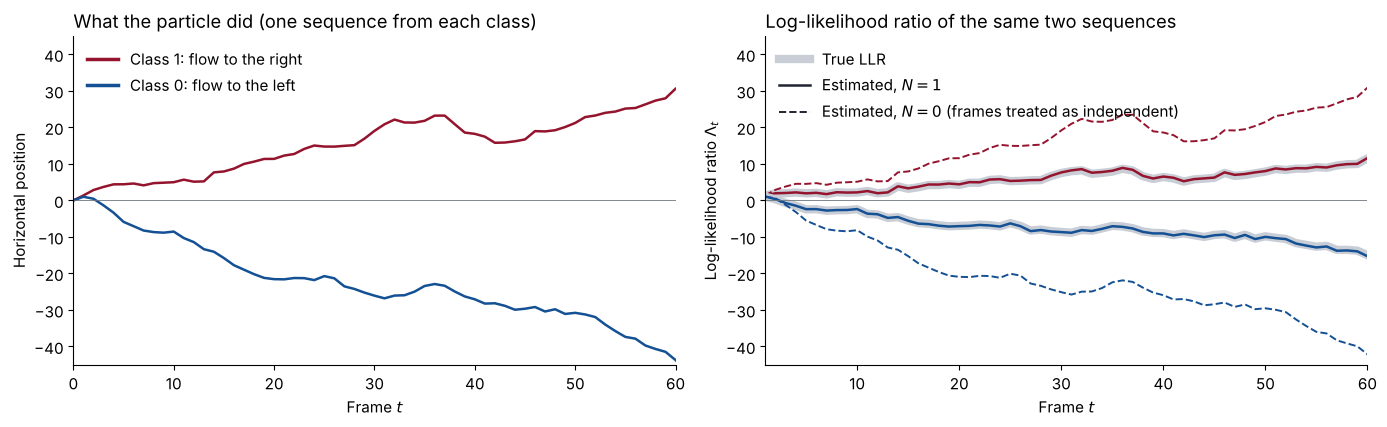

In [10]:
i1, i0 = int(np.where(y_test == 1)[0][0]), int(np.where(y_test == 0)[0][0])   # one sequence from each class
frames = np.arange(1, T + 1)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))

ax = axs[0]
for i, col in ((i1, C1), (i0, C0)):
    ax.plot(np.arange(T + 1), pos_test[i, :, 0], color=col, lw=1.8)
ax.axhline(0, color=GRAY, lw=0.6)
ax.set(xlabel="Frame $t$", ylabel="Horizontal position", xlim=(0, T_SHOW), ylim=(-45, 45))
ax.set_title("What the particle did (one sequence from each class)", loc="left")
ax.legend(handles=class_handles(), frameon=False, loc="upper left")

ax = axs[1]
for i, col in ((i1, C1), (i0, C0)):
    ax.plot(frames, llr_true[i], color=PALE, lw=6, solid_capstyle="round")   # the true LLR is the wide pale line underneath
    ax.plot(frames, llr_n0[i], color=col, lw=1.4, ls="--")
    ax.plot(frames, llr_n1[i], color=col, lw=1.8)
ax.axhline(0, color=GRAY, lw=0.6)
ax.set(xlabel="Frame $t$", ylabel=r"Log-likelihood ratio $\Lambda_t$", xlim=(1, T_SHOW), ylim=(-45, 45))
ax.set_title("Log-likelihood ratio of the same two sequences", loc="left")
ax.legend(handles=[Line2D([], [], color=PALE, lw=6, label="True LLR"),
                   Line2D([], [], color=INK, lw=1.8, label="Estimated, $N = 1$"),
                   Line2D([], [], color=INK, lw=1.4, ls="--", label="Estimated, $N = 0$ (frames treated as independent)")],
          frameon=False, loc="upper left")

fig.tight_layout()
plt.show()

**What the figure shows**

- **The estimate with $N=1$ (solid) stays on the true LLR (wide pale line).** The LLR was recovered from the outputs of the classifier alone, without ever using the formula for the true LLR.
- **The estimate with $N=0$ (dashed) grows too fast.** The part of the motion that merely continues because of inertia is counted as new evidence at every frame. In other words, the same evidence is counted more than once. The LLR is overestimated by a factor of about $(1+\rho)/(1-\rho)$.

## 5. SPRT: stop when the LLR reaches a threshold

The SPRT answers "class 1" as soon as the cumulative LLR $\Lambda_t$ reaches $+a$ and "class 0" as soon as it reaches $-a$, and stops there. If neither threshold has been reached by the last frame, it answers according to the sign of the LLR at that frame.

The figure below applies the SPRT with the threshold $a=3$ to the LLR estimated with $N=1$, $\hat\Lambda_t$. Top row: the path of the particle up to the frame at which the SPRT stopped. Bottom row: the LLR of the same sequence.

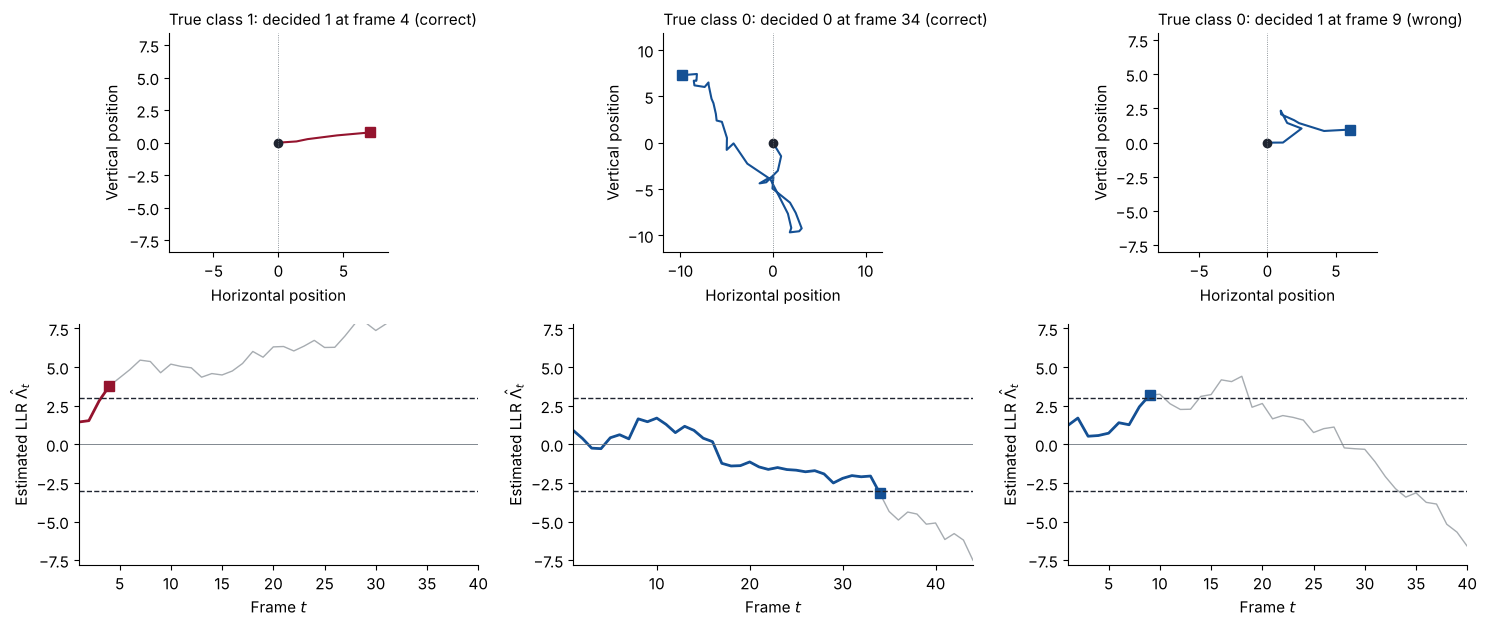

Threshold a = 3.0: decided after 16.8 frames on average, error rate 3.65%


In [11]:
def run_sprt(llr, a):
    """SPRT with the thresholds +a and -a. Returns the decision (0 / 1) and the frame at which it stopped (1-based)."""
    hit = np.abs(llr) >= a
    last = llr.shape[1] - 1
    stop = np.where(hit.any(axis=1), hit.argmax(axis=1), last)           # the last frame if no threshold is reached
    decision = (llr[np.arange(len(llr)), stop] > 0).astype(int)
    return decision, stop + 1


def show_decisions(indices, a, llr=None):
    """For the chosen sequences, draw the path (top) and the LLR (bottom) up to the frame at which the SPRT stopped."""
    llr = llr_n1 if llr is None else llr
    decision, tau = run_sprt(llr, a)
    fig, axs = plt.subplots(2, len(indices), figsize=(5 * len(indices), 6.4), gridspec_kw=dict(height_ratios=[1, 1.1]), squeeze=False)
    for j, i in enumerate(indices):
        col = C1 if y_test[i] == 1 else C0
        ok = decision[i] == y_test[i]
        ax = axs[0, j]
        ax.plot(pos_test[i, :tau[i] + 1, 0], pos_test[i, :tau[i] + 1, 1], color=col, lw=1.5)
        ax.plot(0, 0, "o", color=INK, ms=6)
        ax.plot(pos_test[i, tau[i], 0], pos_test[i, tau[i], 1], "s", color=col, ms=7)
        ax.axvline(0, color=GRAY, lw=0.6, ls=":")
        lim = max(8.0, np.abs(pos_test[i, :tau[i] + 1]).max() * 1.2)
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="Horizontal position", ylabel="Vertical position")
        ax.set_aspect("equal")
        ax.set_title(f"True class {y_test[i]}: decided {decision[i]} at frame {tau[i]} ({'correct' if ok else 'wrong'})", loc="left", fontsize=11)
        ax = axs[1, j]
        t_axis = np.arange(1, llr.shape[1] + 1)
        ax.plot(t_axis, llr[i], color=GRAY, lw=1.0, alpha=0.6)
        ax.plot(t_axis[:tau[i]], llr[i, :tau[i]], color=col, lw=2.0)
        ax.plot(tau[i], llr[i, tau[i] - 1], "s", color=col, ms=7)
        ax.axhline(a, color=INK, lw=1.0, ls="--")
        ax.axhline(-a, color=INK, lw=1.0, ls="--")
        ax.axhline(0, color=GRAY, lw=0.6)
        ax.set(xlabel="Frame $t$", ylabel=r"Estimated LLR $\hat{\Lambda}_t$", xlim=(1, max(40, tau[i] + 10)), ylim=(-2.6 * a, 2.6 * a))
    fig.tight_layout()
    plt.show()


A_DEMO = 3.0
decision_demo, tau_demo = run_sprt(llr_n1, A_DEMO)
correct = decision_demo == y_test
i_fast = int(np.where(correct & (tau_demo <= np.percentile(tau_demo, 15)))[0][0])     # a sequence that was decided quickly
i_slow = int(np.where(correct & (tau_demo >= np.percentile(tau_demo, 90)))[0][0])     # a sequence that took a long time
i_wrong = int(np.where(~correct)[0][0]) if (~correct).any() else i_slow                # a sequence that was decided wrongly
show_decisions([i_fast, i_slow, i_wrong], A_DEMO)
print(f"Threshold a = {A_DEMO}: decided after {tau_demo.mean():.1f} frames on average, error rate {100 * (~correct).mean():.2f}%")

Easy sequences are decided quickly, while confusing ones take longer. The rightmost column is an error: the particle happened to move the wrong way in the early frames, and the LLR reached the opposite threshold.

`show_decisions([index, index, ...], threshold)` draws the same figure for any sequences and any threshold. Raise or lower the threshold and see how the stopping frame and the correctness change.

### Speed-accuracy tradeoff (SAT) curve

Sweep the threshold from small to large values and record the mean number of frames and the error rate each time. This gives one SAT curve, and no retraining is needed.

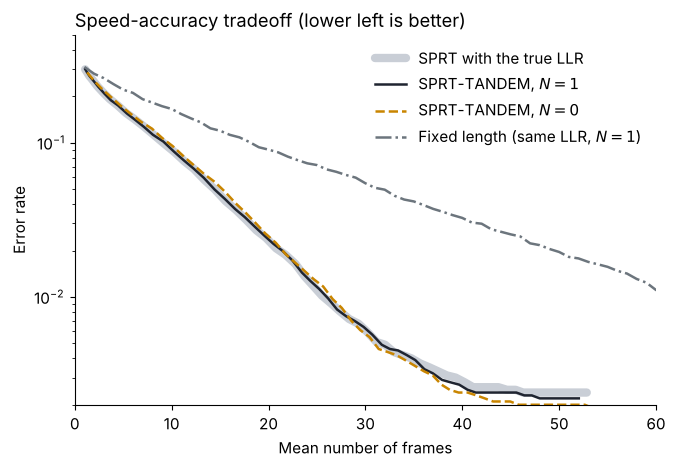

Error rate 5%: fixed length needs 32 frames, SPRT-TANDEM (N = 1) needs 14.4 frames on average
Error rate 1%: fixed length needs 63 frames, SPRT-TANDEM (N = 1) needs 26.1 frames on average


In [12]:
def sat_curve(llr, y, thresholds):
    """Sweep the threshold and return the mean number of frames and the error rate for each value."""
    mean_frames, error = [], []
    for a in thresholds:
        decision, tau = run_sprt(llr, a)
        mean_frames.append(tau.mean())
        error.append((decision != y).mean())
    return np.array(mean_frames), np.array(error)


thresholds = np.linspace(0.1, 9.0, 60)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
n, e = sat_curve(llr_true, y_test, thresholds)
ax.plot(n, e, color=PALE, lw=6, solid_capstyle="round", label="SPRT with the true LLR")
n_sprt, e_sprt = sat_curve(llr_n1, y_test, thresholds)
ax.plot(n_sprt, e_sprt, color=INK, lw=1.8, label="SPRT-TANDEM, $N = 1$")
n, e = sat_curve(llr_n0, y_test, thresholds * (1 + RHO) / (1 - RHO))
ax.plot(n, e, color=AMBER, lw=1.8, ls="--", label="SPRT-TANDEM, $N = 0$")
err_fixed = ((llr_n1 > 0).astype(int) != y_test[:, None]).mean(axis=0)          # same LLR, with the number of frames fixed in advance
ax.plot(np.arange(1, T + 1), err_fixed, color=GRAY, lw=1.8, ls="-.", label="Fixed length (same LLR, $N = 1$)")
ax.set(yscale="log", xlim=(0, T_SHOW), ylim=(2e-3, 0.5), xlabel="Mean number of frames", ylabel="Error rate")
ax.set_title("Speed-accuracy tradeoff (lower left is better)", loc="left")
ax.legend(frameon=False)
plt.show()

for target in (0.05, 0.01):
    if (e_sprt <= target).any() and (err_fixed <= target).any():
        k = int(np.argmax(e_sprt <= target))                 # first threshold at which the error rate is at or below the target
        n_fixed = int(np.argmax(err_fixed <= target)) + 1    # first number of frames at which the error rate is at or below the target
        print(f"Error rate {100 * target:.0f}%: fixed length needs {n_fixed} frames, SPRT-TANDEM (N = 1) needs {n_sprt[k]:.1f} frames on average")
    else:
        print(f"An error rate of {100 * target:.0f}% is not reached with sequences of this length")

**What the figure shows**

- **The SPRT curves lie to the lower left of the fixed-length curve.** The same error rate is reached with less than half the number of frames on average.
- **The curve for $N=1$ lies on top of the curve of the SPRT with the true LLR.**
- The curve for $N=0$ is almost at the same place too, even though its LLR was overestimated by a large factor. Compare this with the next figure.

## 6. Threshold and error rate: does the theoretical guarantee hold?

Wald showed that an SPRT that uses the true LLR with the thresholds $\pm a$ **makes each kind of error with probability at most $e^{-a}$**. Choosing the threshold therefore fixes an upper bound on the error rate in advance. (The bound assumes that the SPRT continues until a threshold is reached, which is almost always the case for the thresholds shown below.) Does the guarantee survive when the LLR is estimated?

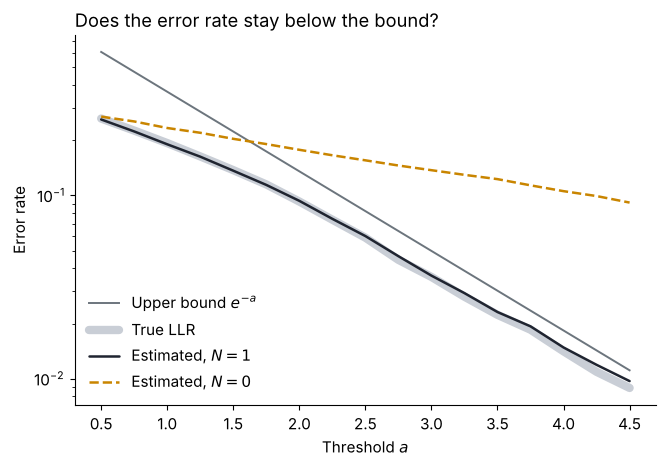

a = 2: bound 13.53% | true LLR  9.26% | N = 1  9.34% | N = 0 17.74%
a = 3: bound  4.98% | true LLR  3.59% | N = 1  3.65% | N = 0 13.73%
a = 4: bound  1.83% | true LLR  1.41% | N = 1  1.48% | N = 0 10.55%


In [13]:
a_grid = np.linspace(0.5, 4.5, 17)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(a_grid, np.exp(-a_grid), color=GRAY, lw=1.4, label="Upper bound $e^{-a}$")
for label, llr, col, lw, ls in (("True LLR", llr_true, PALE, 6, "-"), ("Estimated, $N = 1$", llr_n1, INK, 1.8, "-"), ("Estimated, $N = 0$", llr_n0, AMBER, 1.8, "--")):
    err = [(run_sprt(llr, a)[0] != y_test).mean() for a in a_grid]
    ax.plot(a_grid, err, color=col, lw=lw, ls=ls, solid_capstyle="round", label=label)
ax.set(yscale="log", xlabel="Threshold $a$", ylabel="Error rate")
ax.set_title("Does the error rate stay below the bound?", loc="left")
ax.legend(frameon=False, loc="lower left")
plt.show()

for a in (2.0, 3.0, 4.0):
    row = [f"{100 * (run_sprt(llr, a)[0] != y_test).mean():5.2f}%" for llr in (llr_true, llr_n1, llr_n0)]
    print(f"a = {a:.0f}: bound {100 * np.exp(-a):5.2f}% | true LLR {row[0]} | N = 1 {row[1]} | N = 0 {row[2]}")

**What the figure shows**

- The true LLR and the estimate with $N=1$ stay below the bound. **Choosing the threshold fixes an upper bound on the error rate**, and this guarantee carries over to the estimated LLR. (The curve for $N=1$ is slightly above the curve for the true LLR because of the estimation error.)
- The estimate with $N=0$ is far above the bound. Choosing the threshold $a$ does not give the error rate you intended.

**Think about it**: in the SAT curve, $N=0$ and $N=1$ were almost on top of each other, yet here they differ greatly. Why?

## Summary

| Concept | Where it is in this notebook |
|---|---|
| Likelihood ratio from the posterior ratio (Bayes' theorem) | Difference of the classifier logits (`estimate_llr`) |
| TANDEM formula | `tandem_scores` |
| Training with the ordinary cross-entropy | `multiplet_cross_entropy` |
| SPRT and its thresholds | `run_sprt` |
| SAT curve | `sat_curve` |
| Is the estimate correct? | Comparison with `true_llr` |

For research use, see the official implementation, [SPRT-TANDEM-PyTorch](https://github.com/Akinori-F-Ebihara/SPRT-TANDEM-PyTorch). The functions in this notebook are small rewrites of the following parts of it:

- Sliding windows: `sequential_slice_data` in `utils/data_processing.py`
- Loss: `multiplet_crossentropy` in `models/losses.py`
- TANDEM formula: `calc_llrs` in `utils/performance_metrics.py`

**References**

- A. F. Ebihara, T. Miyagawa, K. Sakurai, and H. Imaoka. Sequential density ratio estimation for simultaneous optimization of speed and accuracy. ICLR 2021.
- A. Wald. Sequential tests of statistical hypotheses. Ann. Math. Statist., 16(2):117–186, 1945.

In [14]:
print(f"Total run time of this notebook: {time.time() - T_START:.0f} s ({device})")

Total run time of this notebook: 28 s (cpu)
